In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
%pip install pandas numpy matplotlib seaborn

  Using cached matplotlib-3.11.2-cp315-cp315-win_amd64.whl.metadata (80 kB)
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached contourpy-1.4.0-cp315-cp315-win_amd64.whl.metadata (3.8 kB)
Using cached matplotlib-3.11.2-cp315-cp315-win_amd64.whl (9.5 MB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Using cached contourpy-1.4.0-cp315-cp315-win_amd64.whl (240 kB)

   ---------------------------------------- 0/3 [contourpy]
   ---------------------------------------- 0/3 [contourpy]
   ---------------------------------------- 0/3 [contourpy]
   ---------------------------------------- 0/3 [contourpy]
   ------------- -------------------------- 1/3 [matplotlib]
   ------------- -------------------------- 1/3 [matplotlib]
   ------------- -------------------------- 1/3 [matplotlib]
   ------------- -------------------------- 1/3 [matplotlib]
   ------------- -------------------------- 1/3 [matplotlib]
   ------------- -------------------------- 1/3 [matpl


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [4]:
data = pd.read_csv('Diabetes_Prediction_Dataset.csv')

In [5]:
data.head()

,Patient_ID,Age,Gender,BMI,Glucose,Blood_Pressure,Cholesterol,Insulin,HbA1c,Smoking_Status,Physical_Activity,Family_History,Diabetes
0,1,58,Male,17.6,140.0,121,177,86,9.7,Current,High,Yes,Yes
1,2,56,Male,31.0,209.0,143,176,244,8.6,Never,Low,No,Yes
2,3,23,Female,19.4,158.0,167,187,37,9.6,Current,Low,No,No
3,4,41,Male,34.6,81.0,174,178,163,11.4,Never,Low,No,No
4,5,31,Female,34.5,88.0,167,282,102,8.2,Never,Low,No,No


In [6]:
data.tail()

,Patient_ID,Age,Gender,BMI,Glucose,Blood_Pressure,Cholesterol,Insulin,HbA1c,Smoking_Status,Physical_Activity,Family_History,Diabetes
4995,4996,66,Male,38.0,115.0,94,146,291,7.8,Former,Moderate,Yes,Yes
4996,4997,34,Male,39.3,164.0,118,281,16,11.3,Never,Low,No,Yes
4997,4998,29,Male,41.3,174.0,172,316,92,8.0,Former,Moderate,No,Yes
4998,4999,45,Female,23.5,73.0,148,136,236,5.5,Current,Low,No,No
4999,5000,62,Female,40.6,183.0,142,290,278,5.4,Never,Low,Yes,Yes


In [7]:
data.shape

(5000, 13)

In [8]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Patient_ID         5000 non-null   int64  
 1   Age                5000 non-null   int64  
 2   Gender             5000 non-null   str    
 3   BMI                4893 non-null   float64
 4   Glucose            4930 non-null   float64
 5   Blood_Pressure     5000 non-null   int64  
 6   Cholesterol        5000 non-null   int64  
 7   Insulin            5000 non-null   int64  
 8   HbA1c              5000 non-null   float64
 9   Smoking_Status     5000 non-null   str    
 10  Physical_Activity  5000 non-null   str    
 11  Family_History     5000 non-null   str    
 12  Diabetes           5000 non-null   str    
dtypes: float64(3), int64(5), str(5)
memory usage: 507.9 KB


In [9]:
data.describe()

,Patient_ID,Age,BMI,Glucose,Blood_Pressure,Cholesterol,Insulin,HbA1c
count,5000.000000,5000.000000,4893.000000,4930.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,2500.500000,48.986400,29.407398,144.456795,143.139200,221.426800,157.746200,7.988300
std,1443.520003,18.173813,7.254359,43.887777,87.414816,57.436379,82.357275,2.017408
min,1.000000,18.000000,17.000000,70.000000,90.000000,120.000000,15.000000,4.500000
25%,1250.750000,33.000000,23.100000,106.000000,112.000000,172.000000,86.000000,6.200000
50%,2500.500000,49.000000,29.400000,144.000000,136.000000,222.000000,158.000000,7.900000
75%,3750.250000,65.000000,35.800000,182.000000,158.000000,271.000000,229.000000,9.800000
max,5000.000000,80.000000,42.000000,220.000000,999.000000,320.000000,300.000000,11.500000


In [10]:
data.isnull().sum()

Patient_ID             0
Age                    0
Gender                 0
BMI                  107
Glucose               70
Blood_Pressure         0
Cholesterol            0
Insulin                0
HbA1c                  0
Smoking_Status         0
Physical_Activity      0
Family_History         0
Diabetes               0
dtype: int64

In [11]:
data.duplicated().sum()

np.int64(0)

In [12]:
for col in ['Gender', 'Smoking_Status', 'Physical_Activity', 'Family_History', 'Diabetes']:
    print(col, data[col].unique())

Gender <StringArray>
['Male', 'Female', 'Unknown']
Length: 3, dtype: str
Smoking_Status <StringArray>
['Current', 'Never', 'Former']
Length: 3, dtype: str
Physical_Activity <StringArray>
['High', 'Low', 'Moderate']
Length: 3, dtype: str
Family_History <StringArray>
['Yes', 'No']
Length: 2, dtype: str
Diabetes <StringArray>
['Yes', 'No']
Length: 2, dtype: str


In [13]:
data = data.drop('Patient_ID', axis=1)

In [14]:

data['Diabetes'] = data['Diabetes'].map({'No': 0, 'Yes': 1})
data['Diabetes'].value_counts()

Diabetes
1    2988
0    2012
Name: count, dtype: int64

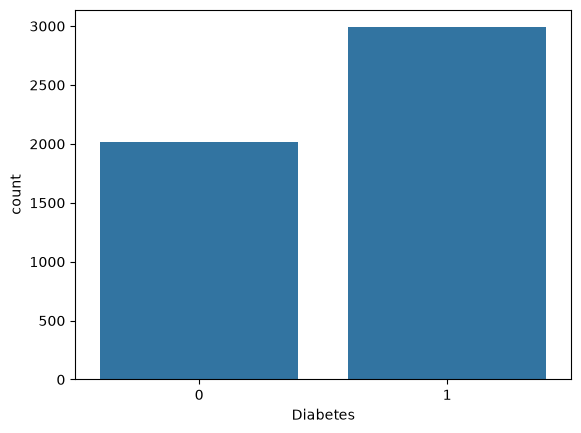

In [15]:
sns.countplot(x=data['Diabetes'])
plt.show()

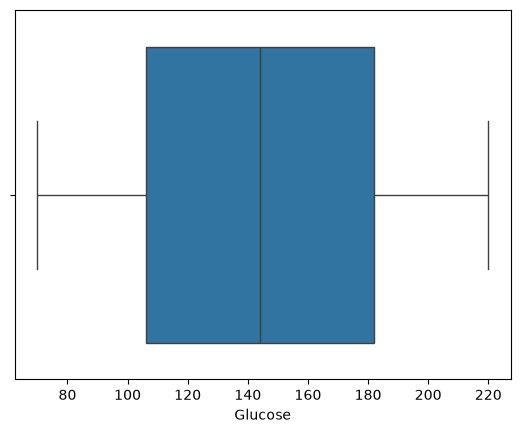

In [16]:
sns.boxplot(data['Glucose'], orient="h")
plt.show()

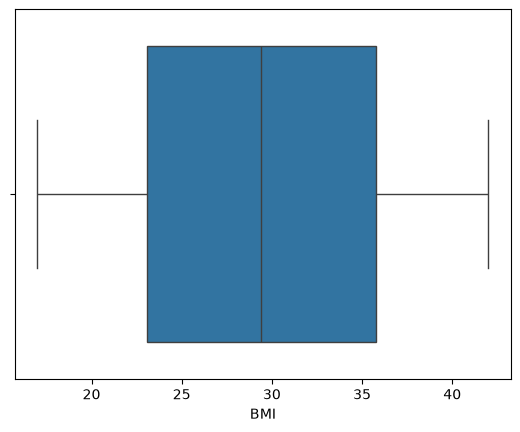

In [17]:
sns.boxplot(data['BMI'], orient="h")
plt.show()

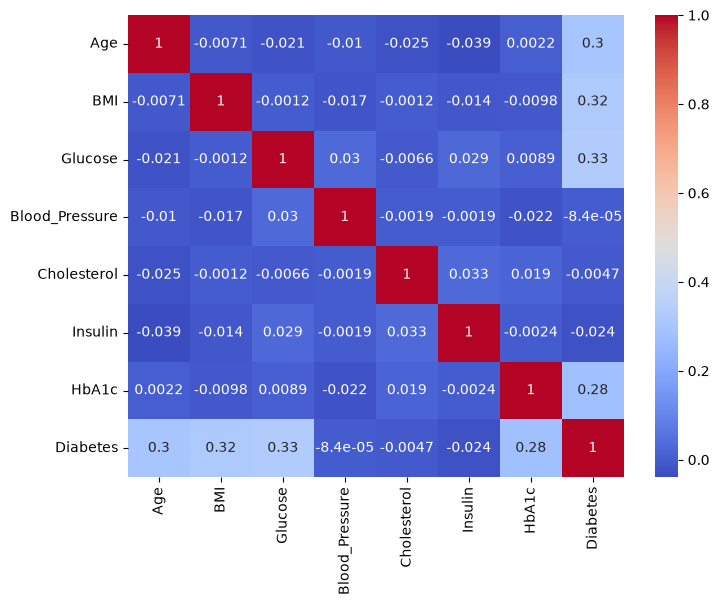

In [18]:
plt.figure(figsize=(8,6))
sns.heatmap(data.select_dtypes(include='number').corr(), annot=True, cmap='coolwarm')
plt.show()

In [19]:
data = pd.get_dummies(data, columns=['Gender', 'Smoking_Status', 'Physical_Activity', 'Family_History'], drop_first=True, dtype=int)

In [20]:
data.head()

,Age,BMI,Glucose,Blood_Pressure,Cholesterol,Insulin,HbA1c,Diabetes,Gender_Male,Gender_Unknown,Smoking_Status_Former,Smoking_Status_Never,Physical_Activity_Low,Physical_Activity_Moderate,Family_History_Yes
0,58,17.6,140.0,121,177,86,9.7,1,1,0,0,0,0,0,1
1,56,31.0,209.0,143,176,244,8.6,1,1,0,0,1,1,0,0
2,23,19.4,158.0,167,187,37,9.6,0,0,0,0,0,1,0,0
3,41,34.6,81.0,174,178,163,11.4,0,1,0,0,1,1,0,0
4,31,34.5,88.0,167,282,102,8.2,0,0,0,0,1,1,0,0


In [21]:
x = data.drop('Diabetes', axis=1)
y = data['Diabetes']

In [22]:
x

,Age,BMI,Glucose,Blood_Pressure,Cholesterol,Insulin,HbA1c,Gender_Male,Gender_Unknown,Smoking_Status_Former,Smoking_Status_Never,Physical_Activity_Low,Physical_Activity_Moderate,Family_History_Yes
0,58,17.6,140.0,121,177,86,9.7,1,0,0,0,0,0,1
1,56,31.0,209.0,143,176,244,8.6,1,0,0,1,1,0,0
2,23,19.4,158.0,167,187,37,9.6,0,0,0,0,1,0,0
3,41,34.6,81.0,174,178,163,11.4,1,0,0,1,1,0,0
4,31,34.5,88.0,167,282,102,8.2,0,0,0,1,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,66,38.0,115.0,94,146,291,7.8,1,0,1,0,0,1,1
4996,34,39.3,164.0,118,281,16,11.3,1,0,0,1,1,0,0
4997,29,41.3,174.0,172,316,92,8.0,1,0,1,0,0,1,0
4998,45,23.5,73.0,148,136,236,5.5,0,0,0,0,1,0,0


In [23]:
y

0       1
1       1
2       0
3       0
4       0
       ..
4995    1
4996    1
4997    1
4998    0
4999    1
Name: Diabetes, Length: 5000, dtype: int64

In [25]:
!pip install scikit-learn xgboost

  Using cached scikit_learn-1.9.1-cp315-cp315-win_amd64.whl.metadata (9.3 kB)
  Using cached xgboost-3.4.1-py3-none-win_amd64.whl.metadata (2.0 kB)
  Using cached scipy-1.18.1-cp315-cp315-win_amd64.whl.metadata (61 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached narwhals-2.29.0-py3-none-any.whl.metadata (15 kB)
  Using cached threadpoolctl-3.8.0-py3-none-any.whl.metadata (29 kB)
  Using cached cloudpickle-3.1.3-py3-none-any.whl.metadata (7.1 kB)
Using cached scikit_learn-1.9.1-cp315-cp315-win_amd64.whl (8.4 MB)
Using cached xgboost-3.4.1-py3-none-win_amd64.whl (48.9 MB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached cloudpickle-3.1.3-py3-none-any.whl (22 kB)
Using cached narwhals-2.29.0-py3-none-any.whl (501 kB)
Using cached scipy-1.18.1-cp315-cp315-win_amd64.whl (37.4 MB)
Using cached threadpoolctl-3.8.0-py3-none-any.whl (32 kB)

   ----- ---------------------------------- 1/7 [scipy]
   ----- ---------------------------------- 1/7 [


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [26]:
from sklearn.model_selection import train_test_split

In [27]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.20, random_state=42)

In [28]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from xgboost import XGBClassifier

In [31]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy='mean')

x_train_clean = imputer.fit_transform(x_train)
x_test_clean = imputer.transform(x_test)

lr = LogisticRegression(max_iter=1000)
lr.fit(x_train_clean, y_train)

rf = RandomForestClassifier()
rf.fit(x_train_clean, y_train)

gb = GradientBoostingClassifier()
gb.fit(x_train_clean, y_train)

xg = XGBClassifier()
xg.fit(x_train_clean, y_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [34]:
x_train = x_train.dropna()
y_train = y_train.loc[x_train.index]

In [36]:
x_test = x_test.dropna()
y_test = y_test.loc[x_test.index]

y_pred1 = lr.predict(x_test)
y_pred2 = rf.predict(x_test)
y_pred3 = gb.predict(x_test)
y_pred4 = xg.predict(x_test)

In [39]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy='mean')
x_test_clean = imputer.fit_transform(x_test)

y_pred1 = lr.predict(x_test_clean)
y_pred2 = rf.predict(x_test_clean)
y_pred3 = gb.predict(x_test_clean)
y_pred4 = xg.predict(x_test_clean)

In [41]:
from sklearn import metrics

In [42]:
score1 = metrics.accuracy_score(y_test, y_pred1)
score2 = metrics.accuracy_score(y_test, y_pred2)
score3 = metrics.accuracy_score(y_test, y_pred3)
score4 = metrics.accuracy_score(y_test, y_pred4)

In [43]:
print(score1, score2, score3, score4)

0.8590673575129534 0.9979274611398964 0.9989637305699481 1.0


In [44]:
final_data = pd.DataFrame({'Models': ['LR', 'RF', 'GB', 'XG'], 'Accuracy': [score1, score2, score3, score4]})
final_data

,Models,Accuracy
0,LR,0.859067
1,RF,0.997927
2,GB,0.998964
3,XG,1.000000


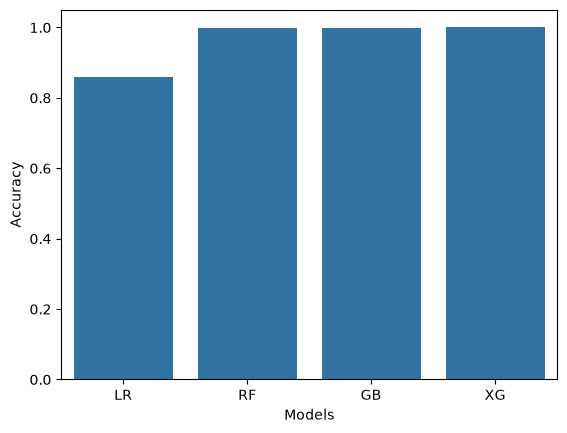

In [45]:
sns.barplot(x=final_data['Models'], y=final_data['Accuracy'])
plt.show()

In [46]:
print(metrics.classification_report(y_test, y_pred4))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       372
           1       1.00      1.00      1.00       593

    accuracy                           1.00       965
   macro avg       1.00      1.00      1.00       965
weighted avg       1.00      1.00      1.00       965



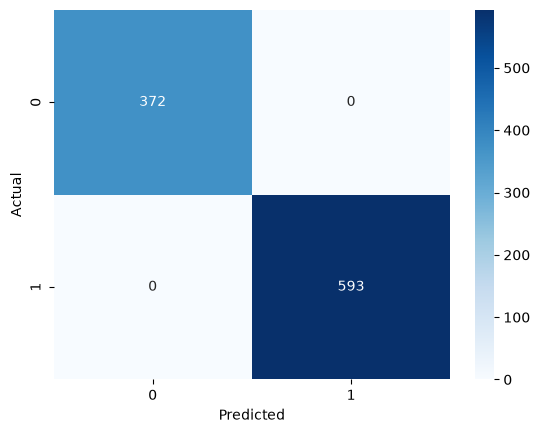

In [47]:
sns.heatmap(metrics.confusion_matrix(y_test, y_pred4), annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [48]:
xg = XGBClassifier()
xg_final = xg.fit(x, y)

In [49]:
import joblib

In [50]:
joblib.dump(xg_final, 'diabetes_predictor')

['diabetes_predictor']

In [51]:
model = joblib.load('diabetes_predictor')

In [52]:
x.columns

Index(['Age', 'BMI', 'Glucose', 'Blood_Pressure', 'Cholesterol', 'Insulin',
       'HbA1c', 'Gender_Male', 'Gender_Unknown', 'Smoking_Status_Former',
       'Smoking_Status_Never', 'Physical_Activity_Low',
       'Physical_Activity_Moderate', 'Family_History_Yes'],
      dtype='str')

In [53]:
new = {'Age': 45, 'BMI': 28.5, 'Glucose': 140, 'Blood_Pressure': 85,
       'Cholesterol': 200, 'Insulin': 100, 'HbA1c': 6.5,
       'Gender_Male': 1, 'Smoking_Status_Never': 1, 'Smoking_Status_Former': 0,
       'Physical_Activity_Low': 0, 'Physical_Activity_Moderate': 1,
       'Family_History_Yes': 1}

data_new = pd.DataFrame(new, index=[0]).reindex(columns=x.columns, fill_value=0)
data_new

,Age,BMI,Glucose,Blood_Pressure,Cholesterol,Insulin,HbA1c,Gender_Male,Gender_Unknown,Smoking_Status_Former,Smoking_Status_Never,Physical_Activity_Low,Physical_Activity_Moderate,Family_History_Yes
0,45,28.5,140,85,200,100,6.5,1,0,0,1,0,1,1


In [54]:
pred = model.predict(data_new)
print("Diabetes" if pred[0] == 1 else "No Diabetes")

No Diabetes


In [55]:
model.predict_proba(data_new)

array([[9.9988276e-01, 1.1725407e-04]], dtype=float32)

In [56]:
import pickle

with open('diabetes_predictor.pkl', 'wb') as file:
    pickle.dump(xg_final, file)

In [57]:
import pickle

with open('diabetes_predictor.pkl', 'rb') as file:
    model = pickle.load(file)

In [58]:
import joblib

joblib.dump(xg_final, 'diabetes_predictor.pkl')

['diabetes_predictor.pkl']

In [59]:
import joblib

model = joblib.load('diabetes_predictor.pkl')